# Balancing a ball on a round board with Q-learning
##### *Bonus practical: coordination in 3D*

#### **The board task**
This is the 3D version of the beam. We now have a **round board** with a ball on it, held on the left and the right side (think of two people carrying a tray). Each side can do two things:
* **move its side up or down** (low, middle, high). This tilts the board left/right, so the ball rolls left/right.
* **rotate its handle** (backward, neutral, forward). This tilts the board forward/backward, so the ball rolls forward/backward.

The important thing is how the two sides combine:
* **Height**: what matters is the *difference*. If both sides go up, the board just moves up and nothing happens to the ball. To tilt the board, the sides have to move in **anti-phase**.
* **Rotation**: what matters is the *sum*. If both sides rotate in the same direction, the tilts add up. If they rotate in opposite directions, they cancel out (they just twist the board). To tilt the board forward, the sides have to move **in phase**.

So the same pair of agents has to coordinate in anti-phase for one movement and in phase for the other.

There is wind again (small random pushes). If the ball rolls off the edge of the board, the episode is over. An episode lasts at most 300 steps.

#### **Setups**
* **one brain**: a single agent controls both sides (it has 9 x 9 = 81 actions)
* **two agents**: each side has its own agent (3 heights x 3 rotations = 9 actions each), and they do not talk to each other

#### **Reward**
Every step the ball is on the board, the agents get a reward that is higher when the ball is closer to the center: $0.1 \times (1 - \text{distance to center})$. Falling off costs -1. On top of that, holding a side away from neutral costs a little effort (-0.015 per unit). The reward is shared.

#### **What does an agent see?**
The position of the ball (x and y) and its velocity (in x and y), each cut into 5 bins. That is 5 x 5 x 5 x 5 = 625 states. An agent does **not** see what the other side is doing.

So remember we have the following components:
* Setup (one brain, two agents)
* Wind
* Effort cost
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* Number of training steps

# Lets get started

In [1]:
import mesa
from mesa.agent import AgentSet
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import copy
from collections import deque

HEIGHTS = [-1, 0, 1]     # low, middle, high
ROTATIONS = [-1, 0, 1]   # backward, neutral, forward
HAND_ACTIONS = list(itertools.product(HEIGHTS, ROTATIONS))  # the 9 things one side can do

# Agent setup: the ball (simple physics)

In [2]:
class Ball(mesa.Agent):
    """A ball rolling on a round board with radius 1. It rolls towards the lower side and gets pushed by the wind."""
    def __init__(self, model, roll_speed=0.003, wind=0.0015):
        super().__init__(model)
        self.roll_speed = roll_speed
        self.wind = wind
        self.reset()

    def reset(self):
        angle = self.model.random.uniform(0, 2 * np.pi)
        distance = self.model.random.uniform(0, 0.3)
        self.x, self.y = distance * np.cos(angle), distance * np.sin(angle)
        self.vx, self.vy = 0.0, 0.0

    def step(self):
        h, r = self.model.height, self.model.rotation
        tilt_x = h["right"] - h["left"]       # height: only the difference matters
        tilt_y = r["left"] + r["right"]       # rotation: the sum matters (opposite rotations cancel)
        self.vx += -self.roll_speed * tilt_x + self.model.rng.normal(0, self.wind)
        self.vy += -self.roll_speed * tilt_y + self.model.rng.normal(0, self.wind)
        self.x += self.vx
        self.y += self.vy

    def distance(self):
        return np.sqrt(self.x ** 2 + self.y ** 2)

    def fallen(self):
        return self.distance() > 1

# Agent setup: the board handler (Q-learning)
A handler holds one side (`sides=["left"]`) or both sides (`sides=["left", "right"]`). For every side it holds, it picks a height and a rotation. The `learn()` method is the same as before.

In [3]:
class BoardHandler(mesa.Agent):
    """A Q-learning agent that holds one or both sides of the board."""
    def __init__(self, model, sides, alpha=0.1, gamma=0.99, epsilon=0.1):
        super().__init__(model)
        self.sides = sides
        self.actions = list(itertools.product(HAND_ACTIONS, repeat=len(sides)))  # 9 for one side, 81 for two
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True
        self.Q = {}

    def observe(self):
        """The state: bins for the ball's x, y, x-velocity and y-velocity."""
        b = self.model.ball
        position_bins = [-0.6, -0.2, 0.2, 0.6]
        velocity_bins = [-0.02, -0.006, 0.006, 0.02]
        return (int(np.digitize(b.x, position_bins)), int(np.digitize(b.y, position_bins)),
                int(np.digitize(b.vx, velocity_bins)), int(np.digitize(b.vy, velocity_bins)))

    def q_values(self, state):
        if state not in self.Q:
            self.Q[state] = np.zeros(len(self.actions))
        return self.Q[state]

    def act(self):
        self.state = self.observe()
        if self.model.random.random() < self.epsilon:
            self.action = self.model.random.randrange(len(self.actions))
        else:
            q = self.q_values(self.state)
            self.action = self.model.random.choice(np.flatnonzero(q == q.max()).tolist())
        for side, (height, rotation) in zip(self.sides, self.actions[self.action]):
            self.model.height[side] = height
            self.model.rotation[side] = rotation

    def learn(self, reward, done):
        if not self.learning:
            return
        if done:
            target = reward
        else:
            target = reward + self.gamma * self.q_values(self.observe()).max()
        td_error = target - self.q_values(self.state)[self.action]
        self.q_values(self.state)[self.action] += self.alpha * td_error

# Model setup
The datacollector collects every step (the batch runner needs that). Next to that, the model keeps an `episode_log` with one row per episode, which we use for the learning curves.

To see how the two sides coordinate, we keep the last 5000 steps of what each side did, and of where the ball was heading (position + 10 x velocity, so where it will be soon). Then we can ask: when the ball heads right, does the left side go down and the right side go up (anti-phase)? When the ball heads forward, do both sides rotate the same way (in phase)?

In [4]:
SETUPS = {
    "one brain":  [["left", "right"]],
    "two agents": [["left"], ["right"]],
}

class BoardModel(mesa.Model):
    def __init__(self, setup="two agents", wind=0.0015, roll_speed=0.003, effort_cost=0.015,
                 max_steps=300, alpha=0.1, gamma=0.99, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.setup = setup
        self.max_steps = max_steps
        self.effort_cost = effort_cost
        self.height = {"left": 0, "right": 0}
        self.rotation = {"left": 0, "right": 0}
        self.ball = Ball(self, roll_speed=roll_speed, wind=wind)
        self.handlers = AgentSet(
            [BoardHandler(self, sides, alpha=alpha, gamma=gamma, epsilon=epsilon) for sides in SETUPS[setup]],
            random=self.random)

        self.t = 0
        self.episode = 0
        self.recent = deque(maxlen=200)      # lengths of the last 200 episodes
        self.history = deque(maxlen=5000)    # what the sides did and where the ball was heading
        self.recent_balance_time = 0
        self.recent_success_rate = 0
        self.episode_log = []
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "episode": "episode",
                "recent_balance_time": "recent_balance_time",
                "recent_success_rate": "recent_success_rate",
            }
        )

    def coordination(self):
        """How does each side follow the ball? (correlations over the last 5000 steps)"""
        h = pd.DataFrame(self.history, columns=["height_left", "height_right", "rotation_left",
                                                "rotation_right", "ball_heading_x", "ball_heading_y"])
        return pd.Series({
            "left height  ~ ball heading x": h["height_left"].corr(h["ball_heading_x"]),
            "right height ~ ball heading x": h["height_right"].corr(h["ball_heading_x"]),
            "left rotation  ~ ball heading y": h["rotation_left"].corr(h["ball_heading_y"]),
            "right rotation ~ ball heading y": h["rotation_right"].corr(h["ball_heading_y"]),
        })

    def new_episode(self):
        self.recent.append(self.t)
        self.recent_balance_time = np.mean(self.recent)
        self.recent_success_rate = np.mean([l == self.max_steps for l in self.recent])
        self.episode += 1
        self.episode_log.append({"episode": self.episode, "episode_length": self.t})
        self.t = 0
        self.ball.reset()

    def step(self):
        self.handlers.do("act")
        b = self.ball
        self.history.append((self.height["left"], self.height["right"], self.rotation["left"],
                             self.rotation["right"], b.x + 10 * b.vx, b.y + 10 * b.vy))
        b.step()
        self.t += 1

        done = b.fallen()
        effort = sum(abs(v) for v in self.height.values()) + sum(abs(v) for v in self.rotation.values())
        reward = -1.0 if done else 0.1 * (1 - b.distance()) - self.effort_cost * effort   # shared reward
        self.handlers.do("learn", reward, done)

        if done or self.t >= self.max_steps:
            self.new_episode()
        self.datacollector.collect(self)   # every step (the batch runner needs this)

# Lets train
We train both setups for 600,000 steps (this is a harder task than the beam, so it takes longer: a few minutes).

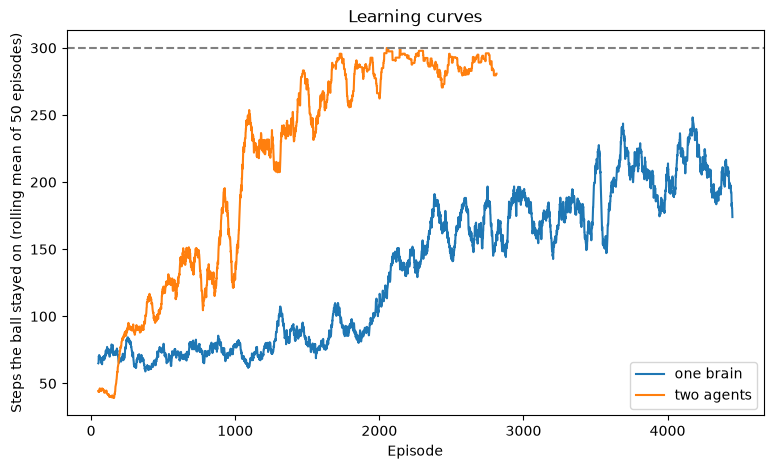

In [5]:
def train(n_steps=600_000, **params):
    model = BoardModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

trained = {setup: train(setup=setup, rng=1) for setup in SETUPS}

fig, ax = plt.subplots(figsize=(9, 5))
for setup, model in trained.items():
    df = pd.DataFrame(model.episode_log)
    ax.plot(df["episode"], df["episode_length"].rolling(50).mean(), label=setup)
ax.axhline(300, color="grey", linestyle="--")
ax.set_xlabel("Episode")
ax.set_ylabel("Steps the ball stayed on (rolling mean of 50 episodes)")
ax.set_title("Learning curves")
ax.legend()
plt.show()

# How do the two sides coordinate?
If the ball heads to the right (+x), the board should tilt so that the right side is higher: right side up, left side down. So we expect a **negative** correlation for the left height and a **positive** one for the right height (anti-phase). For rotation both sides should do the same thing, so we expect **two positive** correlations (in phase).

                                 one brain  two agents
left height  ~ ball heading x         0.08       -0.16
right height ~ ball heading x         0.23        0.11
left rotation  ~ ball heading y       0.11        0.19
right rotation ~ ball heading y       0.16        0.14


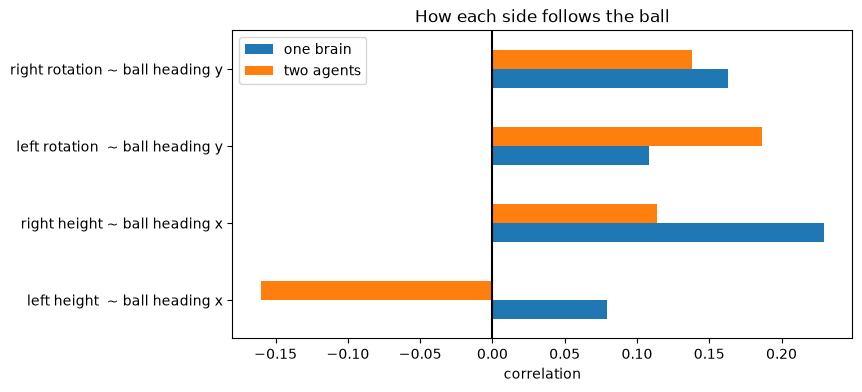

In [6]:
coordination = pd.DataFrame({setup: model.coordination() for setup, model in trained.items()})
print(coordination.round(2))

coordination.plot.barh(figsize=(8, 4))
plt.axvline(0, color="black")
plt.title("How each side follows the ball")
plt.xlabel("correlation")
plt.show()

# Make a custom visualization so we can watch the board in 3D
Again we pass a trained model, so press play and not reset. Exploration is set low.

In [7]:
@solara.component
def BoardVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()
    fig = plt.Figure(figsize=(6, 5))
    ax = fig.add_subplot(projection="3d")
    h, r = model.height, model.rotation
    slope_x = 0.15 * (h["right"] - h["left"])   # left/right tilt from the heights
    slope_y = 0.15 * (r["left"] + r["right"])   # forward/backward tilt from the rotations
    lift = 0.15 * (h["left"] + h["right"])      # both up = the board just moves up
    # the board: a disc
    radius, angle = np.meshgrid(np.linspace(0, 1, 10), np.linspace(0, 2 * np.pi, 40))
    X, Y = radius * np.cos(angle), radius * np.sin(angle)
    ax.plot_surface(X, Y, lift + slope_x * X + slope_y * Y, color="burlywood", alpha=0.7)
    # the handles
    for side, sx in [("left", -1), ("right", 1)]:
        ax.scatter(sx, 0, lift + slope_x * sx, s=150, c="black", marker="s")
    # the ball
    b = model.ball
    ax.scatter(b.x, b.y, lift + slope_x * b.x + slope_y * b.y + 0.08, s=200, c="tab:red")
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_zlim(-0.8, 0.8)
    ax.set_xlabel("x (left - right)")
    ax.set_ylabel("y (back - front)")
    ax.set_title(f"{model.setup}: episode {model.episode}, step {model.t}")
    solara.FigureMatplotlib(fig)

model = trained["two agents"]   # try the one brain too
for handler in model.handlers:
    handler.epsilon = 0.05

page = SolaraViz(model, components=[BoardVisualization], name="Board balancing with Q-learning")
page

Cannot show ipywidgets in text

# Batch run
Both setups, two runs each. (This takes several minutes.)

  0%|          | 0/4 [00:00<?, ?it/s]

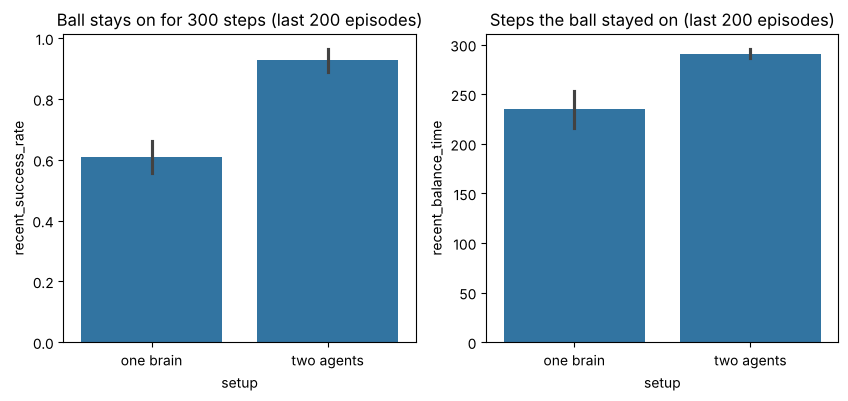

In [8]:
params = {"setup": list(SETUPS)}

results = mesa.batch_run(
    BoardModel,
    parameters=params,
    iterations=2,
    max_steps=600_000,
    number_processes=1,
    data_collection_period=-1,   # only collect at the end
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./board_batch_run.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(results, x="setup", y="recent_success_rate", ax=axes[0])
sns.barplot(results, x="setup", y="recent_balance_time", ax=axes[1])
axes[0].set_title("Ball stays on for 300 steps (last 200 episodes)")
axes[1].set_title("Steps the ball stayed on (last 200 episodes)")
plt.show()

# Experiments for you
1. **One brain or two agents?** The one brain has 81 actions, each agent only 9. What does that do to learning? Train the one brain much longer (e.g., 3 million steps). Does it catch up?
2. **Anti-phase and in-phase.** Look at the coordination plot. Nobody told the agents that height needs anti-phase and rotation needs in-phase. Where does it come from? Why are the correlations far from -1 and +1?
3. **Effort.** Set `effort_cost=0`. What happens to how well they balance, and to the coordination plot? Why could a cost for moving make coordination *clearer*?
4. **Wind.** Try `wind=0.003`. Which setup suffers most?
5. **Division of labor.** Maybe one side does most of the tilting left/right and the other most of the tilting forward/backward. How would you check this? (Hint: look at `model.history`.)
6. **Partner swap.** Use the partner swap code from the beam notebook (adapted to `model.handlers`). Does a mixed team still work here?
7. **Reward.** Change the reward back to the beam reward (+0.1 per step, -1 for falling off). What happens, and why does rewarding "closer to the center" help?